Dataset download

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.sparse as sp
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

!wget -q -O data/YelpChi.zip https://github.com/YingtongDou/CARE-GNN/raw/master/data/YelpChi.zip
!wget -q -O data/Amazon.zip  https://github.com/YingtongDou/CARE-GNN/raw/master/data/Amazon.zip
!cd data && unzip -o -q YelpChi.zip && unzip -o -q Amazon.zip
!ls -la data

total 463312
drwxr-xr-x 2 root root      4096 Oct 20 06:25 .
drwxr-xr-x 4 root root      4096 Oct 20 06:25 ..
-rw-rw-r-- 1 root root 222634416 Aug 20  2020 Amazon.mat
-rw-r--r-- 1 root root  26122297 Oct 20 06:25 Amazon.zip
-rw-rw-r-- 1 root root 207676376 Aug 20  2020 YelpChi.mat
-rw-r--r-- 1 root root  17980652 Oct 20 06:25 YelpChi.zip


Inspect dataset contents

In [2]:
yelp_mat = sio.loadmat("data/YelpChi.mat")
amazon_mat = sio.loadmat("data/Amazon.mat")

print("YelpChi:", [k for k in yelp_mat.keys() if not k.startswith("__")])
print("Amazon: ", [k for k in amazon_mat.keys() if not k.startswith("__")])

YelpChi: ['homo', 'net_rur', 'net_rtr', 'net_rsr', 'features', 'label']
Amazon:  ['homo', 'net_upu', 'net_usu', 'net_uvu', 'features', 'label']


Graph statistics and homophily

In [3]:
def load_dataset(mat, rels, labeled_start=0):
    X = mat["features"]
    X = X.toarray() if sp.issparse(X) else np.asarray(X)
    y = np.asarray(mat["label"]).flatten().astype(int)
    adj = {r: sp.csr_matrix(mat[r]) for r in rels}
    return dict(X=X, y=y, adj=adj, start=labeled_start)

# The first 3,305 Amazon nodes are unlabeled; all Yelp nodes are labeled
yelp = load_dataset(yelp_mat, ["net_rur", "net_rtr", "net_rsr"], 0)
amazon = load_dataset(amazon_mat, ["net_upu", "net_usu", "net_uvu"], 3305)

def stats(name, ds):
    X, y, adj, start = ds["X"], ds["y"], ds["adj"], ds["start"]
    N = len(y)
    labeled = np.zeros(N, bool)
    labeled[start:] = True

    print(f"=== {name} ===")
    print("Nodes:", N, "| Labeled nodes:", labeled.sum(), "| Features:", X.shape[1])
    print(f"Fraud rate among labeled nodes: {y[labeled].mean():.2%}")

    rows = []
    for r, A in adj.items():
        A = A.copy()
        A.setdiag(0)
        A.eliminate_zeros()
        deg = np.asarray(A.sum(axis=1)).flatten()
        coo = A.tocoo()
        m = labeled[coo.row] & labeled[coo.col]
        yr, yc = y[coo.row[m]], y[coo.col[m]]
        rows.append({
            "relation": r,
            "edges": A.nnz // 2,
            "mean_degree": round(deg.mean(), 1),
            "isolated_%": round((deg == 0).mean() * 100, 1),
            "P(fraud nbr | fraud node)": round(yc[yr == 1].mean(), 3),
            "P(fraud nbr | benign node)": round(yc[yr == 0].mean(), 3),
        })
    return pd.DataFrame(rows)

yelp_stats = stats("YelpChi", yelp)
display(yelp_stats)
amazon_stats = stats("Amazon", amazon)
display(amazon_stats)

=== YelpChi ===
Nodes: 45954 | Labeled nodes: 45954 | Features: 32
Fraud rate among labeled nodes: 14.53%


,relation,edges,mean_degree,isolated_%,P(fraud nbr | fraud node),P(fraud nbr | benign node)
0,net_rur,49315,2.1,48.1,0.909,0.002
1,net_rtr,573616,25.0,1.1,0.176,0.141
2,net_rsr,3402743,148.1,0.1,0.186,0.132


=== Amazon ===
Nodes: 11944 | Labeled nodes: 8639 | Features: 25
Fraud rate among labeled nodes: 9.50%


,relation,edges,mean_degree,isolated_%,P(fraud nbr | fraud node),P(fraud nbr | benign node)
0,net_upu,175608,29.4,14.4,0.177,0.124
1,net_usu,3566479,597.2,0.8,0.067,0.023
2,net_uvu,1036737,173.6,0.7,0.064,0.020


Data splitting, metrics, and features

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

def make_split(ds, seed):
    N = len(ds["y"])
    idx = np.arange(ds["start"], N)
    tr, rest = train_test_split(idx, train_size=0.4, stratify=ds["y"][idx], random_state=seed)
    va, te = train_test_split(rest, train_size=1/3, stratify=ds["y"][rest], random_state=seed)
    return tr, va, te

def calc_metrics(y, p):
    k = int(y.sum())
    top = np.argsort(-p)[:k]
    return {"roc_auc": roc_auc_score(y, p),
            "pr_auc": average_precision_score(y, p),
            "recall@k": y[top].sum() / k}

def neighbor_mean(A, X):
    A = A.copy(); A.setdiag(0); A.eliminate_zeros()
    deg = np.asarray(A.sum(axis=1)).flatten()
    inv = 1.0 / np.maximum(deg, 1)
    return sp.diags(inv) @ A @ X, deg

def graph_features(ds):
    parts = [ds["X"]]
    for A in ds["adj"].values():
        agg, deg = neighbor_mean(A, ds["X"])
        parts += [agg, np.log1p(deg)[:, None]]
    return np.hstack(parts)

yelp["X_graph"] = graph_features(yelp)
amazon["X_graph"] = graph_features(amazon)
print("Yelp features:", yelp["X"].shape[1], "->", yelp["X_graph"].shape[1])
print("Amazon features:", amazon["X"].shape[1], "->", amazon["X_graph"].shape[1])

Yelp features: 32 -> 131
Amazon features: 25 -> 103


Graph preparation and model

In [5]:
!pip install -q torch_geometric
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GATConv
from torch_geometric.utils import from_scipy_sparse_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def to_edge_index(mat):
    A = sp.csr_matrix(mat["homo"])      # Three relations merged into one adjacency matrix
    A.setdiag(0); A.eliminate_zeros()
    ei, _ = from_scipy_sparse_matrix(A)
    return ei

yelp["ei"] = to_edge_index(yelp_mat)
amazon["ei"] = to_edge_index(amazon_mat)
print("Yelp edges (directed):", yelp["ei"].shape[1])
print("Amazon edges (directed):", amazon["ei"].shape[1])

class GNN(nn.Module):
    def __init__(self, kind, in_dim, hidden=64, heads=4, dropout=0.3):
        super().__init__()
        if kind == "sage":
            self.c1 = SAGEConv(in_dim, hidden)
            self.c2 = SAGEConv(hidden, 2)
        else:  # GAT: attention heads together produce hidden dimensions
            self.c1 = GATConv(in_dim, hidden // heads, heads=heads)
            self.c2 = GATConv(hidden, 2, heads=1)
        self.dropout = dropout

    def forward(self, x, ei):
        x = F.dropout(x, self.dropout, self.training)
        x = F.relu(self.c1(x, ei))
        x = F.dropout(x, self.dropout, self.training)
        return self.c2(x, ei)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.3 MB/s eta 0:00:00a 0:00:01
device: cuda
Yelp edges (directed): 7693958
Amazon edges (directed): 8796784


Training a single model

In [6]:
def run_gnn(ds, kind, seed, epochs=200):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va, te = make_split(ds, seed)          # Same splits as XGBoost for this seed

    scaler = StandardScaler().fit(ds["X"][tr]) # Fit the scaler on training data only
    x = torch.tensor(scaler.transform(ds["X"]), dtype=torch.float32, device=device)
    y = torch.tensor(ds["y"], device=device)
    ei = ds["ei"].to(device)
    tr_t, va_t, te_t = [torch.tensor(i, device=device) for i in (tr, va, te)]

    model = GNN(kind, x.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    w = torch.tensor([1.0, (y[tr_t] == 0).sum().item() / (y[tr_t] == 1).sum().item()],
                     device=device)

    best_val, best = -1, None
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        out = model(x, ei)
        F.cross_entropy(out[tr_t], y[tr_t], weight=w).backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = model(x, ei).softmax(-1)[:, 1].cpu().numpy()
        val_pr = average_precision_score(ds["y"][va], p[va])
        if val_pr > best_val:                  # Select the best epoch using validation PR-AUC
            best_val = val_pr
            best = calc_metrics(ds["y"][te], p[te])
            best["best_epoch"] = epoch
    return best

# Run one quick test with a single seed to check runtime and memory usage
import time
t0 = time.time()
print(run_gnn(yelp, "sage", seed=0))
print("Seconds:", round(time.time() - t0, 1))

{'roc_auc': np.float64(0.8710181810010327), 'pr_auc': np.float64(0.6288111130666091), 'recall@k': np.float64(0.5683264694870835), 'best_epoch': 194}
Seconds: 31.4


Try more epochs

In [7]:
t0 = time.time()
print(run_gnn(yelp, "sage", seed=0, epochs=800))
print("Seconds:", round(time.time() - t0, 1))

{'roc_auc': np.float64(0.8777998736586177), 'pr_auc': np.float64(0.6442868594997365), 'recall@k': np.float64(0.5784350430550356), 'best_epoch': 780}
Seconds: 126.6


Relation-specific edges and a new model

In [8]:
def rel_edge_indices(ds):
    out = []
    for A in ds["adj"].values():
        A = sp.csr_matrix(A)
        A.setdiag(0); A.eliminate_zeros()
        ei, _ = from_scipy_sparse_matrix(A)
        out.append(ei)
    return out

yelp["ei_rel"] = rel_edge_indices(yelp)
amazon["ei_rel"] = rel_edge_indices(amazon)

class RelSAGE(nn.Module):
    def __init__(self, in_dim, n_rel, hidden=64, dropout=0.3):
        super().__init__()
        self.c1 = nn.ModuleList([SAGEConv(in_dim, hidden) for _ in range(n_rel)])
        self.c2 = nn.ModuleList([SAGEConv(hidden, 2) for _ in range(n_rel)])
        self.dropout = dropout

    def forward(self, x, eis):
        x = F.dropout(x, self.dropout, self.training)
        h = F.relu(sum(c(x, ei) for c, ei in zip(self.c1, eis)))
        h = F.dropout(h, self.dropout, self.training)
        return sum(c(h, ei) for c, ei in zip(self.c2, eis))

Updated run_gnn function

In [9]:
def run_gnn(ds, kind, seed, epochs=200):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va, te = make_split(ds, seed)

    scaler = StandardScaler().fit(ds["X"][tr])
    x = torch.tensor(scaler.transform(ds["X"]), dtype=torch.float32, device=device)
    y = torch.tensor(ds["y"], device=device)
    tr_t, va_t, te_t = [torch.tensor(i, device=device) for i in (tr, va, te)]

    if kind == "rel":
        ei = [e.to(device) for e in ds["ei_rel"]]
        model = RelSAGE(x.shape[1], len(ei)).to(device)
    else:
        ei = ds["ei"].to(device)
        model = GNN(kind, x.shape[1]).to(device)

    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    w = torch.tensor([1.0, (y[tr_t] == 0).sum().item() / (y[tr_t] == 1).sum().item()],
                     device=device)

    best_val, best = -1, None
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        out = model(x, ei)
        F.cross_entropy(out[tr_t], y[tr_t], weight=w).backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = model(x, ei).softmax(-1)[:, 1].cpu().numpy()
        val_pr = average_precision_score(ds["y"][va], p[va])
        if val_pr > best_val:
            best_val = val_pr
            best = calc_metrics(ds["y"][te], p[te])
            best["best_epoch"] = epoch
    return best

t0 = time.time()
print(run_gnn(yelp, "rel", seed=0, epochs=500))
print("Seconds:", round(time.time() - t0, 1))

{'roc_auc': np.float64(0.9294826211016035), 'pr_auc': np.float64(0.7540744010996939), 'recall@k': np.float64(0.6795207787345563), 'best_epoch': 425}
Seconds: 88.6


In [10]:
def add_deg(ds):
    cols = []
    for A in ds["adj"].values():
        A = sp.csr_matrix(A).copy(); A.setdiag(0); A.eliminate_zeros()
        cols.append(np.log1p(np.asarray(A.sum(axis=1)).flatten())[:, None])
    ds["X_deg"] = np.hstack([ds["X"]] + cols)

add_deg(yelp); add_deg(amazon)
print(yelp["X_deg"].shape, amazon["X_deg"].shape)

def run_gnn(ds, kind, seed, epochs=200, xkey="X"):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va, te = make_split(ds, seed)

    scaler = StandardScaler().fit(ds[xkey][tr])
    x = torch.tensor(scaler.transform(ds[xkey]), dtype=torch.float32, device=device)
    y = torch.tensor(ds["y"], device=device)
    tr_t = torch.tensor(tr, device=device)

    if kind == "rel":
        ei = [e.to(device) for e in ds["ei_rel"]]
        model = RelSAGE(x.shape[1], len(ei)).to(device)
    else:
        ei = ds["ei"].to(device)
        model = GNN(kind, x.shape[1]).to(device)

    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    w = torch.tensor([1.0, (y[tr_t] == 0).sum().item() / (y[tr_t] == 1).sum().item()],
                     device=device)

    best_val, best = -1, None
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        out = model(x, ei)
        F.cross_entropy(out[tr_t], y[tr_t], weight=w).backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = model(x, ei).softmax(-1)[:, 1].cpu().numpy()
        val_pr = average_precision_score(ds["y"][va], p[va])
        if val_pr > best_val:
            best_val = val_pr
            best = calc_metrics(ds["y"][te], p[te])
            best["best_epoch"] = epoch
    return best

print(run_gnn(yelp, "rel", seed=0, epochs=500, xkey="X_deg"))

(45954, 35) (11944, 28)
{'roc_auc': np.float64(0.934330278792475), 'pr_auc': np.float64(0.7589935771400879), 'recall@k': np.float64(0.6821415200299513), 'best_epoch': 307}


In [11]:
print(run_gnn(amazon, "rel", seed=0, epochs=500, xkey="X_deg"))

{'roc_auc': np.float64(0.9736105670486389), 'pr_auc': np.float64(0.8690099611701623), 'recall@k': np.float64(0.7963525835866262), 'best_epoch': 67}


In [12]:
import time
rows = []
t0 = time.time()
for name, ds in [("YelpChi", yelp), ("Amazon", amazon)]:
    for label, kind, xkey, ep in [
        ("GraphSAGE (merged graph)", "sage", "X", 500),
        ("R-GraphSAGE (separate relations + degree)", "rel", "X_deg", 500),
    ]:
        for seed in range(5):
            r = run_gnn(ds, kind, seed, epochs=ep, xkey=xkey)
            r = {k: float(v) for k, v in r.items()}
            r.update(dataset=name, model=label, seed=seed)
            rows.append(r)
            print(name, label, seed, round(r["pr_auc"], 3),
                  "| time:", round(time.time() - t0), "s")

res_gnn = pd.DataFrame(rows)
res_gnn.to_csv("results/yelp_amazon_gnn.csv", index=False)

YelpChi GraphSAGE (merged graph) 0 0.639 | time: 80 s
YelpChi GraphSAGE (merged graph) 1 0.636 | time: 160 s
YelpChi GraphSAGE (merged graph) 2 0.646 | time: 241 s
YelpChi GraphSAGE (merged graph) 3 0.639 | time: 321 s
YelpChi GraphSAGE (merged graph) 4 0.633 | time: 401 s
YelpChi R-GraphSAGE (separate relations + degree) 0 0.761 | time: 484 s
YelpChi R-GraphSAGE (separate relations + degree) 1 0.766 | time: 567 s
YelpChi R-GraphSAGE (separate relations + degree) 2 0.769 | time: 651 s
YelpChi R-GraphSAGE (separate relations + degree) 3 0.768 | time: 734 s
YelpChi R-GraphSAGE (separate relations + degree) 4 0.764 | time: 817 s
Amazon GraphSAGE (merged graph) 0 0.877 | time: 890 s
Amazon GraphSAGE (merged graph) 1 0.876 | time: 963 s
Amazon GraphSAGE (merged graph) 2 0.893 | time: 1035 s
Amazon GraphSAGE (merged graph) 3 0.901 | time: 1108 s
Amazon GraphSAGE (merged graph) 4 0.889 | time: 1181 s
Amazon R-GraphSAGE (separate relations + degree) 0 0.869 | time: 1271 s
Amazon R-GraphSAGE (s

Summary table

In [14]:
from xgboost import XGBClassifier

def run_xgb(ds, key, seed):
    tr, va, te = make_split(ds, seed)
    X, y = ds[key], ds["y"]
    spw = (y[tr] == 0).sum() / (y[tr] == 1).sum()
    m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                      tree_method="hist", random_state=seed, n_jobs=-1)
    m.fit(X[tr], y[tr])
    return calc_metrics(y[te], m.predict_proba(X[te])[:, 1])

rows = []
for name, ds in [("YelpChi", yelp), ("Amazon", amazon)]:
    for label, key in [("XGBoost (без графа)", "X"),
                       ("XGBoost (з графовими ознаками)", "X_graph")]:
        for seed in range(5):
            r = run_xgb(ds, key, seed)
            r.update(dataset=name, model=label, seed=seed)
            rows.append(r)

res_xgb = pd.DataFrame(rows)
res_xgb.to_csv("results/yelp_amazon_xgboost.csv", index=False)

all_res = pd.concat([res_xgb, res_gnn], ignore_index=True)
summary = (all_res.groupby(["dataset", "model"])[["roc_auc", "pr_auc", "recall@k"]]
           .agg(["mean", "std"]).round(3))
summary

roc_auc        pr_auc  \
                                                     mean    std   mean   
dataset model                                                             
Amazon  GraphSAGE (merged graph)                    0.972  0.002  0.887   
        R-GraphSAGE (separate relations + degree)   0.971  0.005  0.885   
        XGBoost (без графа)                         0.975  0.002  0.907   
        XGBoost (з графовими ознаками)              0.983  0.001  0.937   
YelpChi GraphSAGE (merged graph)                    0.880  0.005  0.638   
        R-GraphSAGE (separate relations + degree)   0.936  0.003  0.766   
        XGBoost (без графа)                         0.941  0.004  0.809   
        XGBoost (з графовими ознаками)              0.968  0.002  0.886   

                                                         recall@k         
                                                     std     mean    std  
dataset model                                                             
Amazon  GraphSAGE (merged graph)                   0.011    0.815  0.021  
        R-GraphSAGE (separate relations + degree)  0.013    0.813  0.016  
        XGBoost (без графа)                        0.010    0.845  0.016  
        XGBoost (з графовими ознаками)             0.007    0.867  0.014  
YelpChi GraphSAGE (merged graph)                   0.005    0.581  0.004  
        R-GraphSAGE (separate relations + degree)  0.003    0.685  0.007  
        XGBoost (без графа)                        0.010    0.729  0.009  
        XGBoost (з графовими ознаками)             0.004    0.803  0.005

In [15]:
try:
    res_xgb
except NameError:
    # The session was restarted, so recalculate XGBoost (a few minutes)
    rows = []
    for name, ds in [("YelpChi", yelp), ("Amazon", amazon)]:
        for label, key in [("XGBoost (without graph)", "X"), ("XGBoost (with graph features)", "X_graph")]:
            for seed in range(5):
                r = run_xgb(ds, key, seed)
                r.update(dataset=name, model=label, seed=seed)
                rows.append(r)
    res_xgb = pd.DataFrame(rows)

res_xgb.to_csv("results/yelp_amazon_xgboost.csv", index=False)
all_res = pd.concat([res_xgb, res_gnn], ignore_index=True)
summary = (all_res.groupby(["dataset", "model"])[["roc_auc", "pr_auc", "recall@k"]]
           .agg(["mean", "std"]).round(3))
summary

roc_auc        pr_auc  \
                                                     mean    std   mean   
dataset model                                                             
Amazon  GraphSAGE (merged graph)                    0.972  0.002  0.887   
        R-GraphSAGE (separate relations + degree)   0.971  0.005  0.885   
        XGBoost (без графа)                         0.975  0.002  0.907   
        XGBoost (з графовими ознаками)              0.983  0.001  0.937   
YelpChi GraphSAGE (merged graph)                    0.880  0.005  0.638   
        R-GraphSAGE (separate relations + degree)   0.936  0.003  0.766   
        XGBoost (без графа)                         0.941  0.004  0.809   
        XGBoost (з графовими ознаками)              0.968  0.002  0.886   

                                                         recall@k         
                                                     std     mean    std  
dataset model                                                             
Amazon  GraphSAGE (merged graph)                   0.011    0.815  0.021  
        R-GraphSAGE (separate relations + degree)  0.013    0.813  0.016  
        XGBoost (без графа)                        0.010    0.845  0.016  
        XGBoost (з графовими ознаками)             0.007    0.867  0.014  
YelpChi GraphSAGE (merged graph)                   0.005    0.581  0.004  
        R-GraphSAGE (separate relations + degree)  0.003    0.685  0.007  
        XGBoost (без графа)                        0.010    0.729  0.009  
        XGBoost (з графовими ознаками)             0.004    0.803  0.005

Figure for the report

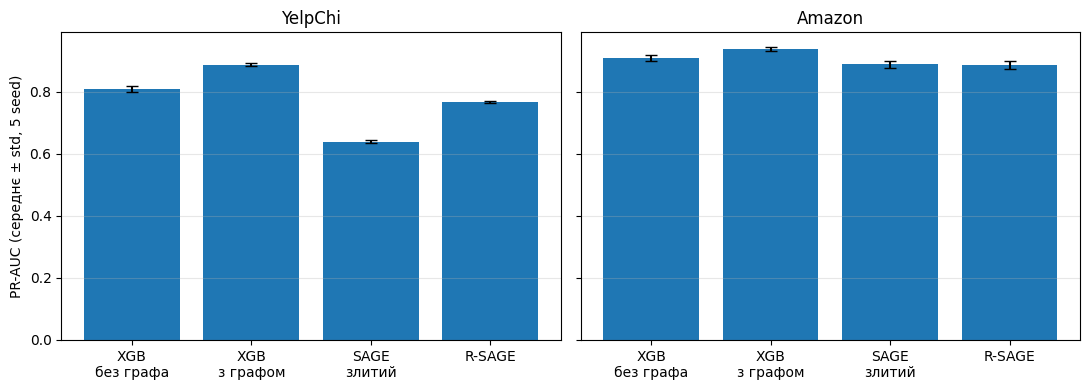

In [18]:
summary_flat = all_res.groupby(["dataset", "model"])["pr_auc"].agg(["mean", "std"]).reset_index()
order = ["XGBoost (без графа)", "XGBoost (з графовими ознаками)",
         "GraphSAGE (merged graph)", "R-GraphSAGE (separate relations + degree)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, ["YelpChi", "Amazon"]):
    d_ = summary_flat[summary_flat.dataset == name].set_index("model").loc[order]
    ax.bar(range(4), d_["mean"], yerr=d_["std"], capsize=4)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["XGB\nбез графа", "XGB\nз графом", "SAGE\nзлитий", "R-SAGE"])
    ax.set_title(name); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("PR-AUC (середнє ± std, 5 seed)")
plt.tight_layout()
plt.savefig("results/figures/yelp_amazon_models.png", dpi=200)
plt.show()